# Exploración de datos: adiciones en contratos de obra pública (SECOP II)

**Pregunta de negocio.** ¿Qué contratos de obra pública firmados en SECOP II
tienen mayor probabilidad de recibir adiciones en tiempo o en valor durante su
ejecución, usando solo información disponible al momento de la firma, para que
la DIARI y las veedurías prioricen su seguimiento preventivo?

**Alcance.**

1. Unidad de análisis: contrato tipo "Obra" en SECOP II.
2. Cobertura: todo el país y todas las entidades; contratos firmados entre el
   1 de enero de 2019 y el 31 de diciembre de 2025.
3. Variable objetivo: `y = 1` si el contrato registra adición en valor (tabla
   Adiciones) o en tiempo (`dias_adicionados > 0`); `y = 0` en otro caso.
4. Variables explicativas: solo información disponible al firmar.

**Fuentes.** Conjuntos abiertos de SECOP II en datos.gov.co, descargados con
`src/ingest.py` el 7 de noviembre de 2026 y versionados con DVC:

1. Contratos Electrónicos (jbjy-vk9h): universo de contratos y adición en
   tiempo.
2. Procesos de Contratación (p6dx-8zbt): precio base, plazo publicado,
   valor adjudicado y respuestas al proceso.
3. Ofertas por Proceso: ofertas por proceso y proveedor, publicada en tres
   tablas por año de registro (bpan-xvj3 hasta 2022, b28v-edj8 2023-2024 y
   wi7w-2nvm 2025-2026).
4. Garantías (gjp9-cutm): pólizas del contrato.
5. Proveedores Registrados (qmzu-gj57): características del contratista.
6. Adiciones (cb9c-h8sn): adición en valor.

**Referentes.** Rodríguez Arévalo (2021), Salazar Mejía (2024) y Reina
Hidalgo (2026). Sus variables y decisiones se contrastan con los datos en la
sección 16.

**Secuencia del análisis.**

1. Carga y cobertura de los cruces.
2. Variable objetivo.
3. Calidad de los datos y valores pactados al firmar.
4. Estado del contrato y desenlace observable.
5. Datos faltantes en variables de firma.
6. Departamento.
7. Modalidad de contratación.
8. Valor y plazo pactados.
9. Mes de firma.
10. Entidades.
11. Adición en tiempo frente a adición en valor.
12. Proveedor y competencia.
13. Objeto, financiación y tiempos del proceso.
14. Garantías.
15. Fuga de información.
16. Contraste con el estado del arte.
17. Conclusiones para el modelado.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedKFold

RAW = Path("../data/raw")
FIG = Path("../reports/figures")
FIG.mkdir(parents=True, exist_ok=True)
FECHA_DESCARGA = pd.Timestamp("2026-11-07")
MIN_DEP, MIN_ENT = 50, 30
UNIDADES = {"D": 1, "S": 7, "M": 30, "A": 365, "H": 1 / 24}
NO_DEFINIDO = {"", "nan", "no definido", "no definida", "no aplica",
               "sin descripcion"}
ETIQUETAS = {
    "valor_inicial": "Valor inicial", "plazo_inicial": "Plazo inicial",
    "valor adjudicado": "Valor adjudicado",
    "oferta ganadora": "Oferta ganadora", "n_ofertas": "Ofertas",
    "modalidad_de_contratacion": "Modalidad",
    "justificacion_modalidad_de": "Justificación de la modalidad",
    "departamento": "Departamento", "orden": "Orden de la entidad",
    "origen_de_los_recursos": "Origen de los recursos",
    "destino_gasto": "Destino del gasto",
    "condiciones_de_entrega": "Condiciones de entrega",
    "tipodocproveedor": "Tipo de documento del proveedor",
    "es_pyme": "Pyme (contrato)", "prov_espyme": "Pyme (registro)",
    "habilita_pago_adelantado": "Pago adelantado",
    "respuestas_al_procedimiento": "Respuestas al proceso",
    "respuestas": "Respuestas al proceso", "proponentes": "Proponentes",
    "prov_fecha_creacion": "Registro del proveedor",
    "prov_tipo_empresa": "Tipo de empresa",
    "prov_tama_o_entidad": "Tamaño de la empresa",
    "nombre_entidad": "Entidad", "mes": "Mes de firma",
    "inicial_sobre_base": "Valor inicial / precio base",
    "antiguedad_prov": "Antigüedad del proveedor (años)",
    "previos_prov": "Contratos previos del proveedor",
    "previos_entidad": "Contratos previos de la entidad",
    "proveedor_repetido": "Proveedor repetido con la entidad",
    "proceso_compartido": "Proceso compartido (lotes)",
    "dias_publicacion_adjudicacion": "Días publicación a adjudicación",
    "dias_adjudicacion_firma": "Días adjudicación a firma",
    "dias_firma_inicio": "Días firma a inicio",
    "segmento_unspsc": "Segmento UNSPSC",
    "fuente_principal": "Fuente principal de recursos",
    "el_contrato_puede_ser_prorrogado": "Prórroga pactada",
    "estado_contrato": "Estado del contrato",
    "exceso_fechas": "Fecha de fin frente a plazo inicial",
    "valor_sobre_adjudicado": "Valor actual / adjudicado",
    "valor_actual": "Valor actual", "plazo_contrato": "Duración actual",
    "valor_pagado_n": "Valor pagado", "valor_facturado_n": "Valor facturado",
    "saldo_cdp_n": "Saldo CDP", "saldo_vigencia_n": "Saldo de vigencia",
    "ultima_act": "Última actualización", "n_polizas": "Pólizas",
    "notificacion_prorroga": "Notificación de prórroga",
}

sns.set_theme(style="whitegrid")
pd.options.display.float_format = "{:,.3f}".format


def fecha(serie):
    """Convierte fechas de SECOP a datetime; las inválidas quedan en NaT."""
    return pd.to_datetime(serie.astype(str).str[:19], errors="coerce",
                          format="ISO8601")


def numero(serie):
    return pd.to_numeric(serie, errors="coerce")


def dias(cantidad, unidad):
    """Convierte una duración con unidad en texto (Dia(s), Mes(es)) a días."""
    return numero(cantidad) * unidad.str.strip().str[0].str.upper().map(
        UNIDADES)


def falta(serie):
    """Marca valores nulos o con texto equivalente a "no definido"."""
    texto = serie.astype(str).str.strip().str.lower()
    return serie.isna() | texto.isin(NO_DEFINIDO)


def tasas(df, por, minimo=0):
    """Contratos y tasa de adición total, en valor y en tiempo por grupo."""
    t = df.groupby(por, observed=True).agg(
        contratos=("y", "size"), y=("y", "mean"),
        valor=("y_valor", "mean"), tiempo=("y_tiempo", "mean"),
    )
    return t[t["contratos"] >= minimo]


def spearman(df, a, b):
    return df[[a, b]].corr("spearman").iloc[0, 1]


def etiqueta(variable):
    return ETIQUETAS.get(variable, variable)


def guardar_figura(nombre):
    plt.tight_layout()
    plt.savefig(FIG / f"{nombre}.png", dpi=150)
    plt.show()

## 1. Carga y cobertura de los cruces

1. Se cargan las seis tablas.
2. Procesos se reduce a una fila por proceso de compra, priorizando la fase
   adjudicada y la publicación más reciente.
3. Ofertas se resume por proceso (ofertas y proponentes) y se identifica la
   oferta ganadora: la del proveedor que firmó el contrato.
4. Se cruzan Procesos y Ofertas por `proceso_de_compra`, Proveedores por
   `codigo_proveedor`, y Adiciones y Garantías por `id_contrato`.
5. Se mide qué proporción de contratos encuentra pareja en cada tabla.

In [2]:
contratos = pd.read_csv(RAW / "contratos_obra.csv", low_memory=False,
                        dtype={"codigo_proveedor": str})
adiciones = pd.read_csv(RAW / "adiciones_valor.csv")
procesos = pd.read_csv(RAW / "procesos_obra.csv", low_memory=False)
ofertas = pd.read_csv(RAW / "ofertas_obra.csv",
                      dtype={"c_digo_proveedor": str})
garantias = pd.read_csv(RAW / "garantias_obra.csv")
proveedores = pd.read_csv(RAW / "proveedores_obra.csv", low_memory=False,
                          dtype={"codigo": str})

tablas = {"Contratos": contratos, "Adiciones": adiciones,
          "Procesos": procesos, "Ofertas": ofertas, "Garantías": garantias,
          "Proveedores": proveedores}
pd.DataFrame({n: t.shape for n, t in tablas.items()},
             index=["filas", "columnas"]).T

,filas,columnas
Contratos,40621,49
Adiciones,5240,4
Procesos,82821,16
Ofertas,934654,4
Garantías,1953,7
Proveedores,11380,11


In [3]:
duplicados = contratos["id_contrato"].duplicated().sum()
print(f"id_contrato duplicados: {duplicados}")
contratos = contratos.drop_duplicates("id_contrato")

procesos["adjudicado_si"] = procesos["adjudicado"].eq("Si")
procesos["publicacion"] = fecha(procesos["fecha_de_publicacion_del"])
proc = (procesos.sort_values(["adjudicado_si", "publicacion"],
                             ascending=False)
        .drop_duplicates("id_del_portafolio"))
prov = proveedores.drop_duplicates("codigo").add_prefix("prov_")

llave = ["id_del_proceso_de_compra", "c_digo_proveedor"]
ofertas = ofertas.groupby(llave, as_index=False).agg(
    n_ofertas=("n_ofertas", "sum"), valor_oferta=("valor_oferta", "max"))
por_proceso = ofertas.groupby("id_del_proceso_de_compra").agg(
    n_ofertas=("n_ofertas", "sum"), proponentes=("c_digo_proveedor", "size"))
ganadora = ofertas.rename(columns={"valor_oferta": "oferta_ganadora"})

df = (contratos
      .merge(proc, how="left", left_on="proceso_de_compra",
             right_on="id_del_portafolio", validate="m:1")
      .merge(prov, how="left", left_on="codigo_proveedor",
             right_on="prov_codigo", validate="m:1")
      .merge(por_proceso, how="left", left_on="proceso_de_compra",
             right_index=True, validate="m:1")
      .merge(ganadora[llave + ["oferta_ganadora"]], how="left",
             left_on=["proceso_de_compra", "codigo_proveedor"],
             right_on=llave, validate="m:1"))
df["firma"] = fecha(df["fecha_de_firma"])
df = df.sort_values("firma", ignore_index=True)
df["anio"] = df["firma"].dt.year
df["mes"] = df["firma"].dt.month

cobertura = pd.Series({
    "Procesos": df["id_del_portafolio"].notna().mean(),
    "Proveedores": df["prov_codigo"].notna().mean(),
    "Ofertas (proceso)": df["n_ofertas"].notna().mean(),
    "Ofertas (oferta ganadora)": df["oferta_ganadora"].notna().mean(),
    "Garantías": df["id_contrato"].isin(garantias["id_contrato"]).mean(),
})
print(f"Contratos de obra 2019-2025: {len(df):,}")
print((cobertura * 100).round(1).rename("% de contratos").to_string())
print("\nCobertura de Ofertas por año de firma (%):")
print((df[["n_ofertas", "oferta_ganadora"]].notna().groupby(df["anio"])
       .mean() * 100).round(1).to_string())
print("\nTipo de documento de los contratistas sin registro en Proveedores:")
print(df.loc[df["prov_codigo"].isna(), "tipodocproveedor"]
      .value_counts().to_string())

id_contrato duplicados: 0


Contratos de obra 2019-2025: 40,621
Procesos                    100.000
Proveedores                  66.600
Ofertas (proceso)            71.300
Ofertas (oferta ganadora)    62.400
Garantías                     1.100

Cobertura de Ofertas por año de firma (%):
      n_ofertas  oferta_ganadora
anio                            
2019     99.000           81.800
2020     79.200           68.700
2021     67.100           57.800
2022     63.200           53.400
2023     69.700           60.100
2024     71.200           65.200
2025     71.300           64.100

Tipo de documento de los contratistas sin registro en Proveedores:
tipodocproveedor
NIT                                10752
No Definido                         2005
Otro                                 584
Cédula de Ciudadanía                 218
Tarjeta de Identidad                   1
Permiso especial de permanencia        1
Cédula de Extranjería                  1


**Hallazgos.**

1. El universo tiene 40.621 contratos de obra firmados entre 2019 y 2025, sin `id_contrato` duplicados.
2. Todos los contratos encuentran su proceso en Procesos de Contratación.
3. Proveedores Registrados cubre el 66,6 % de los contratos. Los faltantes son sobre todo personas jurídicas (NIT), por lo que el vacío no se explica por personas naturales sin registro.
4. Ofertas por Proceso, con sus tres tablas por año, cubre el 71,3 % de los contratos e identifica la oferta ganadora en el 62,4 %. El 91 % de los contratos sin ofertas son de contratación directa o régimen especial, que no reciben ofertas; en las modalidades competitivas la cobertura va de 93 % a 98 %.
5. Garantías cubre el 1,1 % de los contratos: la tabla publicada hoy tiene 48.949 pólizas en total.

## 2. Variable objetivo

1. `y_valor = 1` si el contrato aparece en Adiciones con tipo "Adicion en el
   valor".
2. `y_tiempo = 1` si `dias_adicionados > 0` en Contratos Electrónicos.
3. `y = 1` si ocurre cualquiera de las dos.
4. Se revisa el balance de clases y su estabilidad por año de firma, en total
   y dentro de las modalidades más frecuentes.

In [4]:
df["dias_adic"] = numero(df["dias_adicionados"]).fillna(0)
df["y_valor"] = df["id_contrato"].isin(adiciones["id_contrato"]).astype(int)
df["y_tiempo"] = (df["dias_adic"] > 0).astype(int)
df["y"] = df[["y_valor", "y_tiempo"]].max(axis=1)
print(f"Tasa y = {df['y'].mean():.1%} | valor = {df['y_valor'].mean():.1%}"
      f" | tiempo = {df['y_tiempo'].mean():.1%}")

por_anio = tasas(df, "anio")
print(por_anio.to_string())

principales = df["modalidad_de_contratacion"].value_counts().index[:4]
print("\nTasa de adición en tiempo por año y modalidad:")
print(df[df["modalidad_de_contratacion"].isin(principales)]
      .pivot_table(index="anio", columns="modalidad_de_contratacion",
                   values="y_tiempo", aggfunc="mean").to_string())

Tasa y = 36.4% | valor = 10.5% | tiempo = 28.3%
      contratos     y  valor  tiempo
anio                                
2019       2292 0.353  0.242   0.135
2020       2763 0.346  0.177   0.201
2021       5401 0.346  0.110   0.261
2022       5960 0.338  0.106   0.252
2023       7965 0.297  0.089   0.227
2024       6502 0.349  0.087   0.280
2025       9738 0.463  0.076   0.419

Tasa de adición en tiempo por año y modalidad:
modalidad_de_contratacion  Contratación directa  Licitación pública Obra Publica  Mínima cuantía  Selección Abreviada de Menor Cuantía
anio                                                                                                                                  
2019                                      0.000                            0.235           0.036                                 0.141
2020                                      0.270                            0.210           0.134                                 0.170
2021                           

**Hallazgos.**

1. La tasa global es 36,4 %: 10,5 % con adición en valor y 28,3 % con adición en tiempo. El desbalance es moderado.
2. La tasa total es estable entre 2019 y 2024 (29,7 % a 35,3 %) y sube a 46,3 % en 2025.
3. Las dos componentes se mueven en sentido contrario: la adición en valor baja de 24,2 % (2019) a 7,6 % (2025) y la adición en tiempo sube de 13,5 % a 41,9 %.
4. El aumento de la adición en tiempo ocurre dentro de cada modalidad (licitación pública: 23,5 % en 2019 y 67,0 % en 2025), y la contratación directa no registra días adicionados en 2019. Esto apunta a un cambio en la práctica de registro de `dias_adicionados`, no solo a un cambio en el riesgo.

## 3. Calidad de los datos y valores pactados al firmar

1. Se cuentan valores imposibles o atípicos en valor, plazo, fechas y días
   adicionados.
2. SECOP II no publica el valor firmado: Contratos Electrónicos guarda el
   valor vigente. Se define `valor_inicial` como la mejor aproximación
   disponible antes de la firma: el valor adjudicado (Procesos), si no existe
   la oferta ganadora (Ofertas) y, en último caso, el precio base (Procesos).
   Se descartan como error de digitación los valores mayores a 10 veces el
   precio base. `plazo_inicial` es la duración publicada del proceso.
3. Se verifica si el valor, la duración y la fecha de fin publicados en
   Contratos Electrónicos se actualizan con las adiciones, comparándolos con
   el valor adjudicado y el plazo publicado en Procesos.
4. Se marcan los contratos que comparten proceso con otros (lotes), cuyo
   valor adjudicado y precio base pueden corresponder a todo el proceso.
5. Como análisis de sensibilidad, se mide el subregistro de la adición en
   valor con una definición ampliada: registro en Adiciones o, en procesos de
   un solo contrato, valor actual más de 5 % por encima del valor inicial.
   La variable objetivo del proyecto sigue siendo la registrada.

In [5]:
df["valor_actual"] = numero(df["valor_del_contrato"])
duracion = df["duraci_n_del_contrato"].str.extract(r"(\d+)\s*(\w+)")
df["plazo_contrato"] = dias(duracion[0], duracion[1])
df["inicio"] = fecha(df["fecha_de_inicio_del_contrato"])
df["fin"] = fecha(df["fecha_de_fin_del_contrato"])
plazo = dias(df["duracion"], df["unidad_de_duracion"].astype(str))
df["plazo_inicial"] = plazo.where(plazo.between(1, 3650))

precio_base = numero(df["precio_base"])
precio_base = precio_base.where(precio_base > 0)
adjudicado = numero(df["valor_total_adjudicacion"])
adjudicado = adjudicado.where((adjudicado > 0)
                              & ~(adjudicado > 10 * precio_base))
oferta = df["oferta_ganadora"]
oferta = oferta.where((oferta > 0) & ~(oferta > 10 * precio_base))
df["valor_inicial"] = adjudicado.fillna(oferta).fillna(precio_base)
df["fuente_valor"] = np.select(
    [adjudicado.notna(), oferta.notna(), precio_base.notna()],
    ["adjudicado", "oferta ganadora", "precio base"], default="sin dato")
print("Fuente del valor inicial (%):")
print((df["fuente_valor"].value_counts(normalize=True) * 100).round(1)
      .to_string())
ambos = oferta.notna() & adjudicado.notna()
print(f"\nOferta ganadora a +-1 % del adjudicado: "
      f"{((oferta / adjudicado - 1).abs() < 0.01)[ambos].mean():.1%} "
      f"de {ambos.sum():,} contratos con ambos valores.")
print(f"Adjudicado / precio base (mediana): "
      f"{(adjudicado / precio_base).median():.3f}\n")

chequeos = pd.Series({
    "Valor inicial sin dato": df["valor_inicial"].isna().sum(),
    "Plazo del proceso nulo, 0 o > 10 años":
        df["plazo_inicial"].isna().sum(),
    "Duración del contrato sin número": df["plazo_contrato"].isna().sum(),
    "Sin fecha de inicio": df["inicio"].isna().sum(),
    "Fin anterior a la firma": (df["fin"] < df["firma"]).sum(),
    "Días adicionados > 5 años": (df["dias_adic"] > 1825).sum(),
})
print(pd.DataFrame({"contratos": chequeos,
                    "%": chequeos / len(df) * 100}).round(2).to_string())
print("\nValor inicial (COP):")
print(df["valor_inicial"].describe(percentiles=[.01, .5, .99, .999])
      .to_string())

Fuente del valor inicial (%):
fuente_valor
adjudicado        71.700
precio base       26.400
oferta ganadora    1.700
sin dato           0.200



Oferta ganadora a +-1 % del adjudicado: 85.7% de 24,598 contratos con ambos valores.
Adjudicado / precio base (mediana): 0.980

                                       contratos     %
Valor inicial sin dato                        70 0.170
Plazo del proceso nulo, 0 o > 10 años       3894 9.590
Duración del contrato sin número            2880 7.090
Sin fecha de inicio                          721 1.770
Fin anterior a la firma                      283 0.700
Días adicionados > 5 años                      4 0.010

Valor inicial (COP):
count            40,551.000
mean      2,377,565,740.120
std      15,814,203,563.899
min                   1.000
1%            5,180,074.500
50%         200,000,000.000
99%      38,495,895,790.000
99.9%   220,572,895,983.206
max     893,052,000,000.000


In [6]:
df["proceso_compartido"] = df["proceso_de_compra"].duplicated(
    keep=False).astype(int)
proceso_unico = df["proceso_compartido"] == 0
df["valor_sobre_adjudicado"] = (df["valor_actual"] / adjudicado).where(
    (adjudicado > 0) & proceso_unico)
df["exceso_plazo"] = df["plazo_contrato"] - df["plazo_inicial"]
df["exceso_fechas"] = ((df["fin"] - df["inicio"]).dt.days
                       - df["plazo_inicial"])


def comparar(variable, grupo, umbral):
    datos = df[df[variable].notna()]
    return datos.groupby(grupo)[variable].agg(
        contratos="size", mediana="median",
        p90=lambda s: s.quantile(0.9),
        sobre_umbral=lambda s: (s > umbral).mean())


print("Valor actual / valor adjudicado (procesos de un solo contrato):")
print(comparar("valor_sobre_adjudicado", "y_valor", 1.05).to_string())
print("\nDuración del contrato - plazo del proceso (días):")
print(comparar("exceso_plazo", "y_tiempo", 15).to_string())
print("\n(Fin - inicio) - plazo del proceso (días):")
print(comparar("exceso_fechas", "y_tiempo", 15).to_string())

Valor actual / valor adjudicado (procesos de un solo contrato):
         contratos  mediana   p90  sobre_umbral
y_valor                                        
0            23388    1.000 1.458         0.290
1             3431    1.289 1.500         0.860

Duración del contrato - plazo del proceso (días):
          contratos  mediana     p90  sobre_umbral
y_tiempo                                          
0             24074    0.000  54.000         0.159
1              9842   24.000 210.000         0.524

(Fin - inicio) - plazo del proceso (días):
          contratos  mediana     p90  sobre_umbral
y_tiempo                                          
0             25859    1.000 169.000         0.301
1             10240   97.000 446.000         0.869


In [7]:
print("Contratos en procesos compartidos:",
      f"{df['proceso_compartido'].mean():.1%}")
print(tasas(df, "proceso_compartido").to_string())

crecio = proceso_unico & (df["valor_actual"] > 1.05 * df["valor_inicial"])
df["y_valor_ampliada"] = (df["y_valor"].astype(bool) | crecio).astype(int)
y_ampliada = df[["y_valor_ampliada", "y_tiempo"]].max(axis=1)
print(f"\ny_valor: registrada {df['y_valor'].mean():.1%} | ampliada "
      f"{df['y_valor_ampliada'].mean():.1%}")
print(f"y: registrada {df['y'].mean():.1%} | ampliada "
      f"{y_ampliada.mean():.1%}")
columnas = ["y_valor", "y_valor_ampliada"]
seis = df["modalidad_de_contratacion"].value_counts().index[:6]
print("\nAdición en valor registrada y ampliada por modalidad:")
print(df.groupby("modalidad_de_contratacion")[columnas].mean().loc[seis]
      .to_string())
print("\nPor año de firma:")
print(df.groupby("anio")[columnas].mean().to_string())

Contratos en procesos compartidos: 6.0%
                    contratos     y  valor  tiempo
proceso_compartido                                
0                       38165 0.359  0.102   0.280
1                        2456 0.448  0.155   0.323

y_valor: registrada 10.5% | ampliada 30.6%
y: registrada 36.4% | ampliada 47.4%

Adición en valor registrada y ampliada por modalidad:
                                             y_valor  y_valor_ampliada
modalidad_de_contratacion                                             
Selección Abreviada de Menor Cuantía           0.145             0.393
Contratación directa                           0.028             0.122
Mínima cuantía                                 0.136             0.308
Licitación pública Obra Publica                0.124             0.425
Contratación régimen especial                  0.070             0.233
Contratación régimen especial (con ofertas)    0.078             0.219

Por año de firma:
      y_valor  y_valor_ampliada
a

**Hallazgos.**

1. Los problemas de calidad son acotados: 0,17 % sin valor inicial, 9,6 % sin plazo del proceso válido, 1,8 % sin fecha de inicio y 0,7 % con fin anterior a la firma.
2. El valor inicial tiene una cola extrema (máximo de 8,9 · 10¹¹ COP frente a una mediana de 200 millones), por lo que conviene usarlo en escala logarítmica.
3. `valor_del_contrato` incluye las adiciones: en procesos de un solo contrato, los contratos con adición en valor tienen una razón mediana de 1,29 frente al valor adjudicado y un percentil 90 de 1,50, igual al tope legal del 50 % (Ley 80 de 1993, art. 40). Sin adición la mediana es 1,00.
4. `duraci_n_del_contrato` también se actualiza: supera el plazo del proceso en más de 15 días en el 52,4 % de los contratos con adición en tiempo y en el 15,9 % de los demás.
5. `fecha_de_fin_del_contrato` incorpora las prórrogas: el exceso de (fin - inicio) sobre el plazo del proceso tiene mediana de 97 días con adición en tiempo y de 1 día sin ella.
6. SECOP II no publica el valor firmado. `valor_inicial` se toma del valor adjudicado (71,7 % de los contratos), de la oferta ganadora (1,7 %) o del precio base (26,4 %). La oferta ganadora coincide con el adjudicado a ±1 % en el 85,7 % de los casos y el adjudicado es, en mediana, el 98 % del precio base. `plazo_inicial` es la duración publicada del proceso.
7. El 29,0 % de los contratos sin registro en Adiciones también supera en más de 5 % su valor adjudicado. Esto sugiere adiciones en valor no registradas como tal, es decir, subregistro en `y_valor`.
8. El 6,0 % de los contratos comparte proceso con otros (lotes). Estos contratos tienen más adiciones (44,8 % frente a 35,9 %), por lo que el indicador de proceso compartido entra como variable.
9. Como análisis de sensibilidad, una definición ampliada (registro en Adiciones o valor actual más de 5 % sobre el valor inicial en procesos de un solo contrato) llevaría la adición en valor de 10,5 % a 30,6 % y la tasa total `y` de 36,4 % a 47,4 %.
10. La definición ampliada es estable entre años (27,1 % a 37,7 %), mientras la registrada cae de 24,2 % en 2019 a 7,6 % en 2025. La caída de la adición en valor registrada responde en buena parte a la forma de registro.
11. La ampliación es mayor en las modalidades con menos registro: contratación directa pasa de 2,8 % a 12,2 % y régimen especial de 7,0 % a 23,3 %.
12. Se adopta la definición registrada: mide el acto legal de adición en valor. El crecimiento del valor también puede deberse a reajustes de precios pactados o a correcciones, que legalmente no son adiciones. El subregistro queda como limitación: el modelo estima la probabilidad de una adición registrada como tal.

## 4. Estado del contrato y desenlace observable

1. Se compara la tasa de adición por estado del contrato.
2. Se mide el efecto de filtrar por estado (terminado o cerrado), como propone
   el alcance.
3. Se evalúa un criterio que no depende del desenlace: que el plazo inicial
   haya vencido antes de la fecha de descarga.

In [8]:
print(tasas(df, "estado_contrato")
      .sort_values("contratos", ascending=False).to_string())

terminados = df["estado_contrato"].str.lower().isin(["terminado", "cerrado"])
print(f"\nFiltro por estado (terminado o cerrado): {terminados.sum():,} "
      f"contratos, tasa {df.loc[terminados, 'y'].mean():.1%} frente a "
      f"{df['y'].mean():.1%} en el total.")

fin_pactado = df["inicio"].fillna(df["firma"]) + pd.to_timedelta(
    df["plazo_inicial"], unit="D")
df["vencido"] = (fin_pactado < FECHA_DESCARGA).astype(float).where(
    fin_pactado.notna())
vencidos = tasas(df, ["anio", "vencido"])["y"].unstack().rename(
    columns={0.0: "plazo vigente", 1.0: "plazo vencido"})
vencidos["% vencidos"] = df.groupby("anio")["vencido"].mean() * 100
sin_plazo = df["vencido"].isna().groupby(df["anio"]).mean()
vencidos["% sin plazo"] = sin_plazo * 100
print("\nTasa y por año según si el plazo inicial ya venció:")
print(vencidos.to_string())

                 contratos     y  valor  tiempo
estado_contrato                                
Modificado           14021 0.806  0.135   0.733
terminado            13503 0.172  0.127   0.050
En ejecución          7666 0.032  0.017   0.016
Cerrado               3414 0.158  0.142   0.019
Aprobado              1354 0.035  0.024   0.011
Suspendido             628 0.541  0.057   0.510
cedido                  35 0.171  0.029   0.143

Filtro por estado (terminado o cerrado): 16,917 contratos, tasa 16.9% frente a 36.4% en el total.

Tasa y por año según si el plazo inicial ya venció:
vencido  plazo vigente  plazo vencido  % vencidos  % sin plazo
anio                                                          
2019             1.000          0.352      99.955        2.269
2020             0.500          0.347      99.766        7.311
2021             0.000          0.340      99.838        8.424
2022             0.167          0.339      99.889        9.044
2023             0.190          0.292 

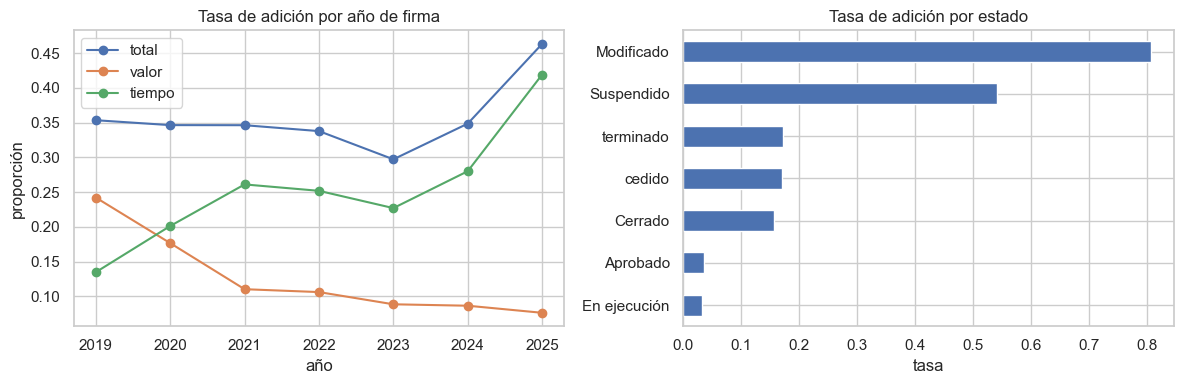

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
por_anio[["y", "valor", "tiempo"]].rename(columns={"y": "total"}).plot(
    marker="o", ax=ax[0])
ax[0].set(title="Tasa de adición por año de firma", xlabel="año",
          ylabel="proporción")
estados = tasas(df, "estado_contrato").sort_values("y")
estados["y"].plot.barh(ax=ax[1], title="Tasa de adición por estado")
ax[1].set(xlabel="tasa", ylabel="")
guardar_figura("01_tasa_anio_estado")

**Hallazgos.**

1. El estado depende del desenlace: "Modificado" tiene 80,6 % de adición y "En ejecución" 3,2 %.
2. Filtrar por estado terminado o cerrado, como propone el alcance, deja 16.917 contratos con una tasa de 16,9 % frente a 36,4 % del total. El filtro excluye justamente los contratos modificados y sesga la muestra.
3. Con el plazo inicial, más del 99 % de los contratos de 2019 a 2024 y el 95,7 % de los de 2025 ya debían haber terminado al momento de la descarga. La censura por contratos aún vigentes es pequeña y se concentra en 2025.
4. La muestra se define por fecha de firma y no por estado; solo se excluyen los contratos cuyo plazo inicial sigue vigente.

## 5. Datos faltantes en variables de firma

1. Se calcula la proporción de nulos o "No definido" en las variables que
   el formulario del tablero pediría al firmar.
2. Se incluyen las fuentes del valor inicial y las variables de Ofertas.
3. Se compara la tasa de adición entre contratos con y sin dato, para saber
   si el faltante es informativo.

modalidad_de_contratacion      0.000
orden                          0.000
origen_de_los_recursos         0.000
es_pyme                        0.000
justificacion_modalidad_de     0.000
respuestas_al_procedimiento    0.000
valor_inicial                  0.200
destino_gasto                  0.200
departamento                   2.400
tipodocproveedor               4.900
habilita_pago_adelantado       7.400
plazo_inicial                  9.600
valor adjudicado              28.300
n_ofertas                     28.700
prov_tipo_empresa             33.400
prov_fecha_creacion           33.400
condiciones_de_entrega        36.200
oferta ganadora               37.700
prov_tama_o_entidad           62.300


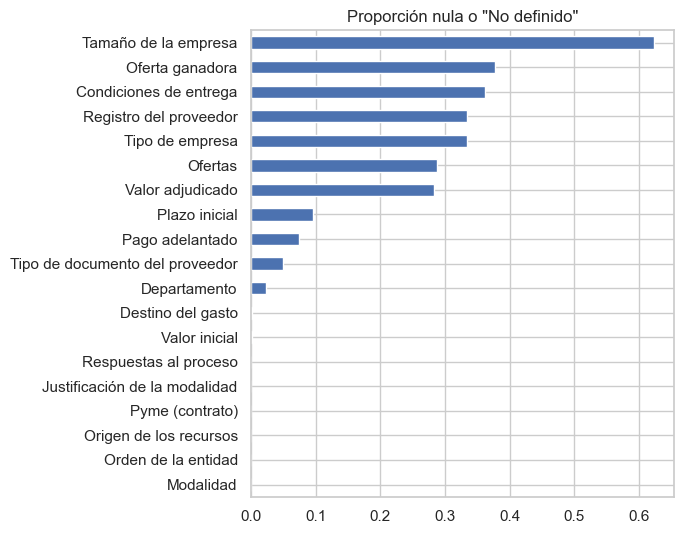


Tasa de adición según si la variable tiene dato:
                                 tasa con dato  tasa sin dato  diferencia
Plazo inicial                            0.362          0.385       0.023
Condiciones de entrega                   0.364          0.364       0.000
Tipo de empresa                          0.326          0.440       0.114
Pago adelantado                          0.367          0.324      -0.044
Tipo de documento del proveedor          0.358          0.476       0.118
Ofertas                                  0.385          0.313      -0.072


In [10]:
variables_firma = [
    "valor_inicial", "plazo_inicial", "modalidad_de_contratacion",
    "departamento", "orden", "origen_de_los_recursos", "destino_gasto",
    "condiciones_de_entrega", "tipodocproveedor", "es_pyme",
    "habilita_pago_adelantado", "justificacion_modalidad_de",
    "respuestas_al_procedimiento", "prov_fecha_creacion",
    "prov_tipo_empresa", "prov_tama_o_entidad",
]
faltantes = pd.Series({v: falta(df[v]).mean() for v in variables_firma})
faltantes["valor adjudicado"] = adjudicado.isna().mean()
faltantes["oferta ganadora"] = oferta.isna().mean()
faltantes["n_ofertas"] = df["n_ofertas"].isna().mean()
faltantes = faltantes.sort_values()
print((faltantes * 100).round(1).rename("% faltante").to_string())

faltantes.rename(index=etiqueta).plot.barh(
    figsize=(7, 5.5), title="Proporción nula o \"No definido\"")
guardar_figura("02_faltantes")

informativas = ["plazo_inicial", "condiciones_de_entrega",
                "prov_tipo_empresa", "habilita_pago_adelantado",
                "tipodocproveedor", "n_ofertas"]
sin_dato = pd.DataFrame({
    v: df.groupby(falta(df[v]))["y"].mean() for v in informativas
}).T.rename(columns={False: "tasa con dato", True: "tasa sin dato"})
sin_dato["diferencia"] = sin_dato["tasa sin dato"] - sin_dato["tasa con dato"]
print("\nTasa de adición según si la variable tiene dato:")
print(sin_dato.rename(index=etiqueta).to_string())

**Hallazgos.**

1. Modalidad, orden, origen de los recursos, justificación de la modalidad y respuestas al proceso no tienen faltantes.
2. Valor inicial (0,17 %), departamento (2,4 %) y tipo de documento del proveedor (4,9 %) tienen pocos faltantes.
3. Plazo inicial (9,6 %) y pago adelantado (7,4 %) requieren imputación con indicador de faltante.
4. Valor adjudicado falta en el 28,3 %, casi todo en contratación directa y régimen especial, donde no hay adjudicación.
5. Condiciones de entrega (36,2 %), datos del proveedor (33,4 %) y tamaño de la empresa (62,3 %) son opcionales en el formulario.
6. Ofertas falta en el 28,7 % de los contratos y la oferta ganadora en el 37,7 %, sobre todo por contratación directa y régimen especial. En el tablero se precargan desde el identificador del proceso.
7. Algunos faltantes son informativos: sin tipo de documento del proveedor la tasa es 47,6 % frente a 35,8 %, y sin registro en Proveedores es 44,0 % frente a 32,6 %. El faltante de condiciones de entrega no cambia la tasa. Los indicadores de faltante deben entrar al modelo.

## 6. Departamento

1. Se calcula la tasa por departamento de la entidad con al menos `MIN_DEP`
   contratos.
2. Se mide la concentración de contratos por departamento.

Departamentos con n >= 50: 31. Tasa entre 18.5% y 50.6%.
              contratos     y  valor  tiempo
departamento                                
Chocó               405 0.185  0.040   0.158
Casanare            570 0.196  0.074   0.135
Caquetá             547 0.203  0.090   0.126
La Guajira          359 0.245  0.053   0.214
Putumayo            470 0.281  0.049   0.247
                                          contratos     y  valor  tiempo
departamento                                                            
Quindío                                         508 0.445  0.096   0.372
Sucre                                           310 0.445  0.090   0.387
Risaralda                                       699 0.454  0.084   0.386
Magdalena                                       588 0.463  0.048   0.429
San Andrés, Providencia y Santa Catalina         85 0.506  0.224   0.341

Departamentos con más contratos:
                            contratos     y  valor  tiempo  % contratos
departament

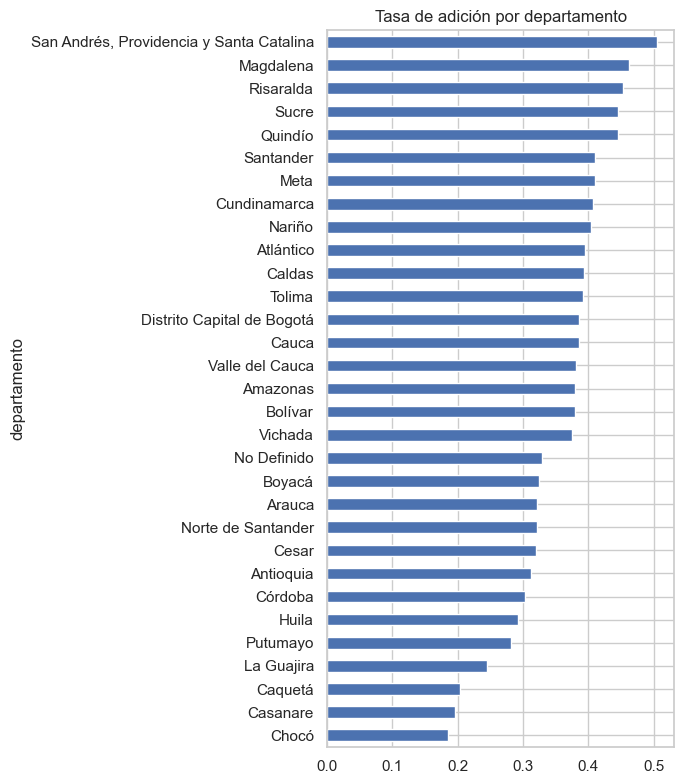

In [11]:
dep = tasas(df, "departamento", MIN_DEP).sort_values("y")
print(f"Departamentos con n >= {MIN_DEP}: {len(dep)}. Tasa entre "
      f"{dep['y'].min():.1%} y {dep['y'].max():.1%}.")
print(dep.head(5).to_string())
print(dep.tail(5).to_string())
mayores = dep.nlargest(5, "contratos")
mayores["% contratos"] = mayores["contratos"] / len(df) * 100
print("\nDepartamentos con más contratos:")
print(mayores.to_string())

dep["y"].plot.barh(figsize=(7, 8), title="Tasa de adición por departamento")
guardar_figura("03_departamento")

**Hallazgos.**

1. Treinta y un departamentos tienen al menos 50 contratos; su tasa va de 18,5 % (Chocó) a 50,6 % (San Andrés).
2. Bogotá concentra el 28,7 % de los contratos con una tasa de 38,6 %, cercana a la global; Antioquia, el 11,1 % con 31,3 %.
3. La variación entre departamentos es amplia pero menor que entre entidades, por lo que el departamento aporta contexto territorial más que poder predictivo propio.

## 7. Modalidad de contratación

1. Se calcula la tasa total, en valor y en tiempo por modalidad.
2. Se identifican modalidades con pocos contratos para agruparlas.

                                                             contratos     y  valor  tiempo
modalidad_de_contratacion                                                                  
Selección Abreviada de Menor Cuantía                             11275 0.381  0.145   0.270
Contratación directa                                              8580 0.324  0.028   0.305
Mínima cuantía                                                    8003 0.261  0.136   0.142
Licitación pública Obra Publica                                   7533 0.518  0.124   0.430
Contratación régimen especial                                     2029 0.271  0.070   0.215
Contratación régimen especial (con ofertas)                       1419 0.407  0.078   0.353
Contratación Directa (con ofertas)                                1369 0.297  0.052   0.269
Seleccion Abreviada Menor Cuantia Sin Manifestacion Interes        257 0.486  0.152   0.381
Licitación pública                                                 156 0.397  0.

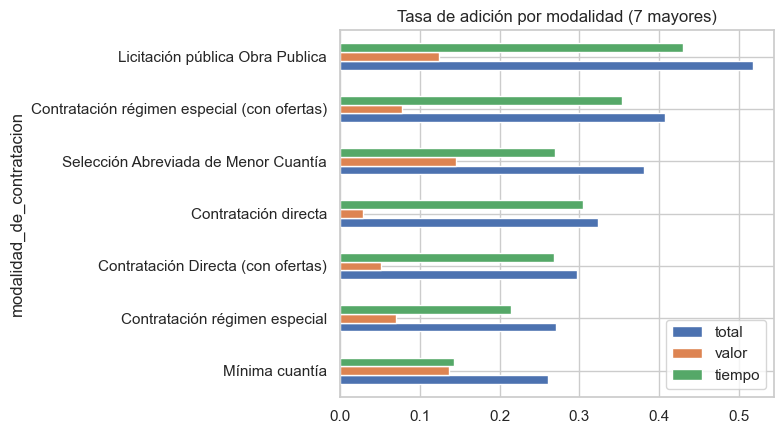

In [12]:
mod = tasas(df, "modalidad_de_contratacion").sort_values(
    "contratos", ascending=False)
print(mod.to_string())
print("Modalidades con menos de 1.000 contratos:",
      (mod["contratos"] < 1000).sum(), "de", len(mod))

mod.head(7)[["y", "valor", "tiempo"]].sort_values("y").rename(
    columns={"y": "total"}).plot.barh(
    figsize=(8, 4.5), title="Tasa de adición por modalidad (7 mayores)")
guardar_figura("04_modalidad")

**Hallazgos.**

1. La licitación pública de obra tiene la tasa más alta (51,8 %), seguida de selección abreviada de menor cuantía (38,1 %), contratación directa (32,4 %) y mínima cuantía (26,1 %).
2. Las modalidades difieren en el tipo de adición: la contratación directa casi no registra adición en valor (2,8 %) pero sí en tiempo (30,5 %); en mínima cuantía ambas son similares (13,6 % en valor y 14,2 % en tiempo).
3. Dos de nueve modalidades tienen menos de 1.000 contratos y son variantes de otras ("Seleccion Abreviada Menor Cuantia Sin Manifestacion Interes" y "Licitación pública"), por lo que se agrupan con su modalidad principal.

## 8. Valor y plazo pactados

1. Se calcula la tasa por decil de valor inicial.
2. Se cruza el decil de valor con rangos de plazo inicial; se ocultan las
   celdas con menos de `MIN_ENT` contratos.
3. Se mide la correlación de Spearman de cada variable con `y`.
4. Se comparan las distribuciones de valor inicial, plazo inicial y
   respuestas al proceso entre contratos con y sin adición.

             contratos     y  valor  tiempo
decil_valor                                
1                 3667 0.166  0.083   0.089
2                 3666 0.238  0.092   0.159
3                 3666 0.299  0.112   0.202
4                 3666 0.255  0.068   0.199
5                 3742 0.351  0.107   0.268
6                 3590 0.368  0.124   0.270
7                 3666 0.419  0.128   0.324
8                 3666 0.445  0.118   0.357
9                 3666 0.527  0.142   0.423
10                3666 0.558  0.100   0.500

Spearman valor ~ y: 0.246 | plazo ~ y: 0.126 | valor ~ plazo: 0.588


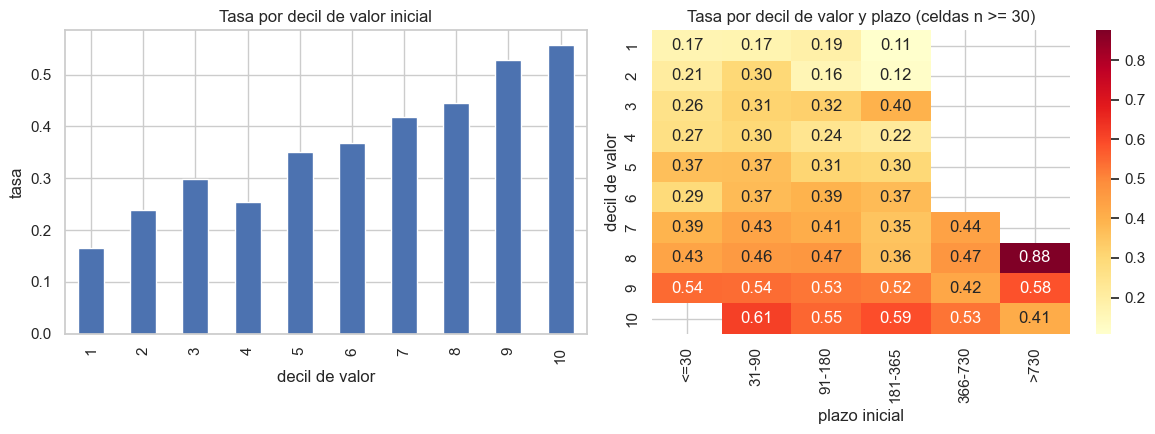

In [13]:
vp = df.dropna(subset=["valor_inicial", "plazo_inicial"]).copy()
vp["decil_valor"] = pd.qcut(vp["valor_inicial"], 10, labels=range(1, 11))
vp["rango_plazo"] = pd.cut(
    vp["plazo_inicial"], [0, 30, 90, 180, 365, 730, 3650],
    labels=["<=30", "31-90", "91-180", "181-365", "366-730", ">730"])
por_decil = tasas(vp, "decil_valor")
print(por_decil.to_string())
print(f"\nSpearman valor ~ y: {spearman(vp, 'valor_inicial', 'y'):.3f} | "
      f"plazo ~ y: {spearman(vp, 'plazo_inicial', 'y'):.3f} | "
      f"valor ~ plazo: "
      f"{spearman(vp, 'valor_inicial', 'plazo_inicial'):.3f}")

celdas = vp.pivot_table(index="decil_valor", columns="rango_plazo",
                        values="y", aggfunc=["mean", "size"], observed=True)
mapa = celdas["mean"].where(celdas["size"] >= MIN_ENT)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
por_decil["y"].plot.bar(ax=ax[0], title="Tasa por decil de valor inicial")
ax[0].set(xlabel="decil de valor", ylabel="tasa")
sns.heatmap(mapa, annot=True, fmt=".2f", cmap="YlOrRd", ax=ax[1])
ax[1].set(title=f"Tasa por decil de valor y plazo (celdas n >= {MIN_ENT})",
          xlabel="plazo inicial", ylabel="decil de valor")
guardar_figura("05_valor_plazo")

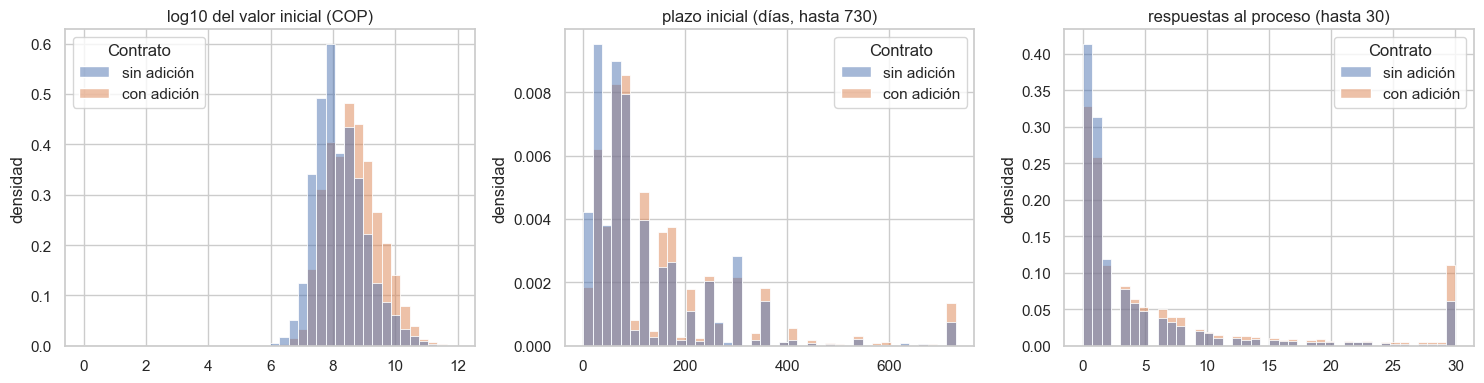

y                                 mediana y=0  mediana y=1
log10 del valor inicial (COP)           8.100        8.599
plazo inicial (días, hasta 730)        80.000       90.000
respuestas al proceso (hasta 30)        1.000        2.000


In [14]:
distribuciones = {
    "log10 del valor inicial (COP)": np.log10(df["valor_inicial"]),
    "plazo inicial (días, hasta 730)": df["plazo_inicial"].clip(upper=730),
    "respuestas al proceso (hasta 30)": numero(
        df["respuestas_al_procedimiento"]).clip(upper=30),
}
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for eje, (nombre, serie) in zip(ax, distribuciones.items()):
    sns.histplot(x=serie, hue=df["y"].map({0: "sin adición",
                                           1: "con adición"}).rename(
                                               "Contrato"),
                 stat="density", common_norm=False, bins=40, ax=eje)
    eje.set(title=nombre, xlabel="", ylabel="densidad")
guardar_figura("11_distribuciones")
print(pd.DataFrame(distribuciones).groupby(df["y"]).median().T
      .rename(columns={0: "mediana y=0", 1: "mediana y=1"}).to_string())

**Hallazgos.**

1. La tasa crece con el valor inicial: 16,6 % en el decil 1 y 55,8 % en el decil 10 (Spearman 0,25).
2. El plazo inicial tiene una relación más débil (Spearman 0,13) y está correlacionado con el valor (0,59), por lo que gran parte de su señal se comparte con el valor.
3. El crecimiento se explica sobre todo por la adición en tiempo (8,9 % a 50,0 %); la adición en valor varía menos entre deciles (6,8 % a 14,2 %).
4. Las distribuciones confirman el patrón: la mediana del valor inicial es 126 millones sin adición y 397 millones con adición; el plazo inicial, 80 y 90 días; las respuestas al proceso, 1 y 2.

## 9. Mes de firma

1. Se compara el volumen de firmas y la tasa de adición por mes.

mes            1       2         3         4         5         6         7         8         9         10        11        12
contratos 546.000 742.000 1,342.000 1,793.000 2,653.000 3,288.000 3,300.000 3,411.000 4,312.000 5,308.000 6,514.000 7,412.000
y           0.368   0.361     0.320     0.313     0.325     0.335     0.366     0.350     0.383     0.356     0.384     0.395
valor       0.158   0.139     0.102     0.119     0.123     0.120     0.126     0.127     0.111     0.104     0.086     0.079
tiempo      0.236   0.247     0.232     0.216     0.224     0.239     0.269     0.253     0.297     0.275     0.318     0.341


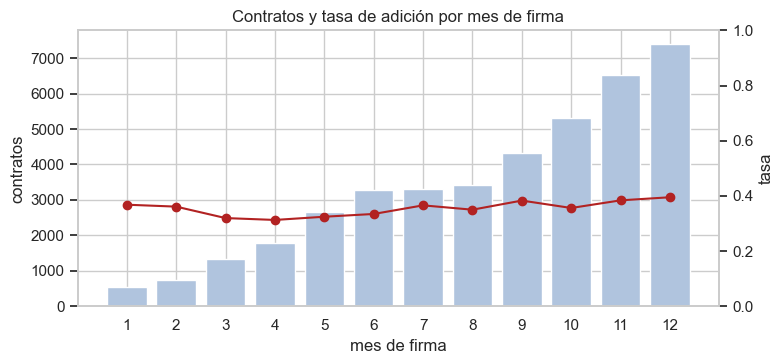

In [15]:
mes = tasas(df, "mes")
print(mes.T.to_string())

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.bar(mes.index, mes["contratos"], color="lightsteelblue")
ax.set(xticks=range(1, 13), xlabel="mes de firma", ylabel="contratos",
       title="Contratos y tasa de adición por mes de firma")
ax2 = ax.twinx()
ax2.plot(mes.index, mes["y"], color="firebrick", marker="o")
ax2.set(ylabel="tasa", ylim=(0, 1))
ax2.grid(False)
guardar_figura("06_mes")

**Hallazgos.**

1. El volumen de firmas crece a lo largo del año: diciembre concentra 7.412 contratos (18,2 %) frente a 546 en enero.
2. La tasa total varía poco (31,3 % a 39,5 %), pero sus componentes se separan: los contratos firmados en noviembre y diciembre tienen más adición en tiempo (31,8 % y 34,1 %) y menos en valor (8,6 % y 7,9 %) que los de enero (23,6 % y 15,8 %).
3. El mes de firma es útil como variable si se modela cada tipo de adición por separado.

## 10. Entidades

1. Se mide la concentración de contratos con adición por entidad.
2. Se describe la dispersión de la tasa entre entidades con al menos
   `MIN_ENT` contratos.
3. Se mide la experiencia de la entidad (contratos de obra firmados antes) y
   si el contratista ya había contratado con ella, contando solo firmas
   anteriores. Rodríguez Arévalo (2021) encontró que la diversidad de
   proveedores y categorías de cada entidad predice las adiciones.

Entidades: 2,378. Las 10 mayores concentran 22.8% de los contratos con adición; las 100 mayores, 51.9%.
                                                              contratos  con_adicion     y
nombre_entidad                                                                            
INVIAS                                                             2725         1271 0.466
INSTITUTO DE CAMINOS Y CONSTRUCCIONES DE CUNDINAMARCA - ICCU       2577          760 0.295
AEROCIVIL                                                          1156          313 0.271
MUNICIPIO DE MANIZALES                                              403          231 0.573
AGENCIA PARA LA INFRAESTRUCTURA DEL META                            277          163 0.588
SECRETARIA DE EDUCACION DE CALI                                     174          155 0.891
MUNICIPIO DE BUCARAMANGA                                            182          138 0.758
GOBERNACION DEL MAGDALENA                                           255      

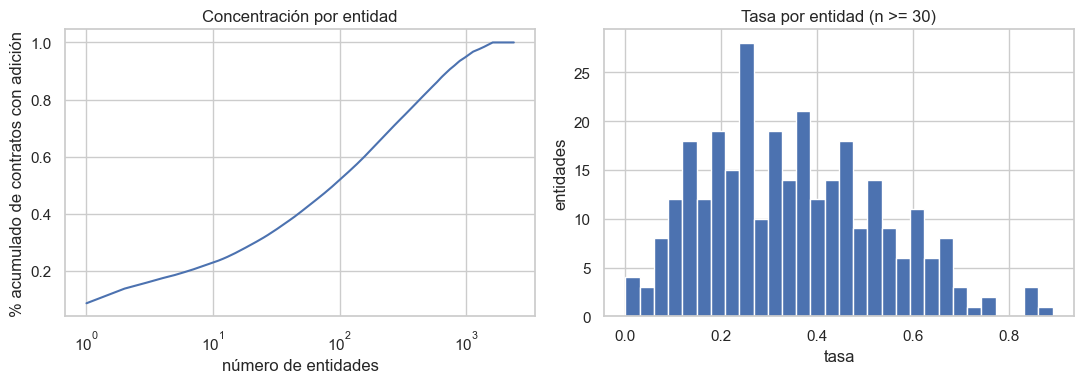


Tasa según contratos de obra previos de la entidad:
         contratos     y  valor  tiempo
previos                                
0             2378 0.341  0.188   0.193
1-4           5448 0.341  0.163   0.211
5-19         10153 0.343  0.111   0.259
20-99        12707 0.364  0.073   0.311
100+          9935 0.404  0.091   0.332

Tasa según si el contratista ya había contratado con la entidad:
                    contratos     y  valor  tiempo
proveedor_repetido                                
0                       28818 0.384  0.113   0.298
1                       11803 0.316  0.088   0.244


In [16]:
ent = df.groupby("nombre_entidad").agg(
    contratos=("y", "size"), con_adicion=("y", "sum"), y=("y", "mean"),
).sort_values("con_adicion", ascending=False)
acumulado = ent["con_adicion"].cumsum() / ent["con_adicion"].sum()
print(f"Entidades: {len(ent):,}. Las 10 mayores concentran "
      f"{acumulado.iloc[9]:.1%} de los contratos con adición; "
      f"las 100 mayores, {acumulado.iloc[99]:.1%}.")
print(ent.head(10).to_string())
grandes = ent[ent["contratos"] >= MIN_ENT]
print(f"Entidades con n >= {MIN_ENT}: {len(grandes)} "
      f"({grandes['contratos'].sum() / len(df):.1%} de los contratos). "
      f"Tasa p10, p50, p90: "
      f"{grandes['y'].quantile([.1, .5, .9]).round(3).tolist()}")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(range(1, len(ent) + 1), acumulado.values)
ax[0].set(xscale="log", xlabel="número de entidades",
          ylabel="% acumulado de contratos con adición",
          title="Concentración por entidad")
grandes["y"].hist(bins=30, ax=ax[1])
ax[1].set(title=f"Tasa por entidad (n >= {MIN_ENT})", xlabel="tasa",
          ylabel="entidades")
guardar_figura("07_entidades")

df["previos_entidad"] = df.groupby("nombre_entidad").cumcount()
df["proveedor_repetido"] = df.duplicated(
    ["nombre_entidad", "codigo_proveedor"]).astype(int)
experiencia = pd.cut(df["previos_entidad"], [-1, 0, 4, 19, 99, np.inf],
                     labels=["0", "1-4", "5-19", "20-99", "100+"])
print("\nTasa según contratos de obra previos de la entidad:")
print(tasas(df.assign(previos=experiencia), "previos").to_string())
print("\nTasa según si el contratista ya había contratado con la entidad:")
print(tasas(df, "proveedor_repetido").to_string())

**Hallazgos.**

1. Hay 2.378 entidades; las 10 mayores concentran el 22,8 % de los contratos con adición y las 100 mayores el 51,9 %.
2. INVIAS es la entidad con más contratos (2.725) y una tasa de 46,6 %.
3. Entre las 300 entidades con al menos 30 contratos, que suman el 69,1 % del total, la tasa va de 12,7 % (p10) a 60,8 % (p90).
4. La entidad es la variable de firma más informativa, pero su alta cardinalidad exige codificación con suavizado y una evaluación con entidades no vistas.
5. La tasa total sube poco con la experiencia de la entidad (34,1 % sin contratos de obra previos y 40,4 % con 100 o más), pero cambia su composición: la adición en valor baja de 18,8 % a 9,1 % y la de tiempo sube de 19,3 % a 33,2 %. Las entidades con más contratos registran más los días adicionados.
6. Cuando el contratista ya había contratado con la entidad, la tasa es menor (31,6 % frente a 38,4 %).

## 11. Adición en tiempo frente a adición en valor

1. Se cruzan ambos tipos de adición.
2. Se comparan sus tasas por modalidad para decidir si conviene modelarlas por
   separado.
3. Se mide la magnitud: número de adiciones en valor por contrato, como en
   Salazar Mejía (2024), y días adicionados frente al plazo inicial.

In [17]:
print(pd.crosstab(df["y_valor"], df["y_tiempo"], margins=True).to_string())
p_v_t = df.loc[df["y_tiempo"] == 1, "y_valor"].mean()
p_t_v = df.loc[df["y_valor"] == 1, "y_tiempo"].mean()
print(f"P(valor | tiempo) = {p_v_t:.3f} | P(tiempo | valor) = {p_t_v:.3f}")
print(mod.head(6)[["valor", "tiempo"]].to_string())

n_adiciones = adiciones.groupby("id_contrato").size()
print("\nAdiciones en valor por contrato con adición en valor:")
print(n_adiciones.describe(percentiles=[.5, .9, .99]).round(2).to_string())
con_tiempo = df[df["y_tiempo"] == 1]
extension = con_tiempo["dias_adic"] / con_tiempo["plazo_inicial"]
print("\nDías adicionados y extensión relativa al plazo inicial:")
print(pd.DataFrame({"dias_adicionados": con_tiempo["dias_adic"],
                    "extension_relativa": extension})
      .describe(percentiles=[.5, .9]).round(2).to_string())

y_tiempo      0      1    All
y_valor                      
0         25827  10509  36336
1          3308    977   4285
All       29135  11486  40621
P(valor | tiempo) = 0.085 | P(tiempo | valor) = 0.228
                                             valor  tiempo
modalidad_de_contratacion                                 
Selección Abreviada de Menor Cuantía         0.145   0.270
Contratación directa                         0.028   0.305
Mínima cuantía                               0.136   0.142
Licitación pública Obra Publica              0.124   0.430
Contratación régimen especial                0.070   0.215
Contratación régimen especial (con ofertas)  0.078   0.353

Adiciones en valor por contrato con adición en valor:
count   4,285.000
mean        1.220
std         0.570
min         1.000
50%         1.000
90%         2.000
99%         4.000
max        10.000

Días adicionados y extensión relativa al plazo inicial:
       dias_adicionados  extension_relativa
count        11,486.000 

**Hallazgos.**

1. Solo 977 contratos tienen ambos tipos de adición.
2. P(valor | tiempo) = 8,5 % y P(tiempo | valor) = 22,8 %: los dos desenlaces son casi independientes.
3. Los perfiles por modalidad son distintos, lo que respalda dos probabilidades separadas en el tablero (tiempo y valor) además de la combinada.
4. La adición en valor rara vez se repite: mediana de 1 adición por contrato y percentil 90 de 2. En obra, el conteo que propone Salazar Mejía (2024) aporta poca información frente a la variable binaria.
5. La adición en tiempo es grande: mediana de 60 días, equivalente al 50 % del plazo inicial, y en el 10 % de los casos supera 2,7 veces ese plazo. La extensión relativa sirve como indicador de magnitud en el tablero (elemento A).

## 12. Proveedor y competencia

1. Antigüedad del proveedor en SECOP II al firmar (Proveedores Registrados).
2. Contratos de obra previos del mismo proveedor dentro del periodo, contados
   solo con firmas anteriores para no usar información futura.
3. Respuestas al proceso (Procesos) y su consistencia con las ofertas y los
   proponentes de Ofertas por Proceso.
4. Razón entre el valor inicial y el precio base, que mide qué tan por
   debajo del presupuesto se adjudicó.

Proveedor registrado después de la firma: 0.5%



antiguedad_prov (cobertura 66.6%, Spearman con y 0.094)
             contratos     y  valor  tiempo
rango                                      
(-inf, 0.0]        381 0.218  0.042   0.189
(0.0, 1.0]        6274 0.272  0.088   0.197
(1.0, 3.0]        7672 0.317  0.130   0.211
(3.0, 5.0]        6777 0.336  0.129   0.231
(5.0, inf]        5955 0.391  0.109   0.310



previos_prov (cobertura 100.0%, Spearman con y -0.036)
             contratos     y  valor  tiempo
rango                                      
(-1.0, 0.0]      20885 0.383  0.105   0.304
(0.0, 2.0]        8547 0.342  0.117   0.247
(2.0, 9.0]        7020 0.354  0.110   0.270
(9.0, inf]        4169 0.335  0.079   0.273



respuestas (cobertura 100.0%, Spearman con y 0.114)
             contratos     y  valor  tiempo
rango                                      
(-1.0, 0.0]      11640 0.313  0.041   0.282
(0.0, 1.0]        8934 0.321  0.100   0.249
(1.0, 2.0]        3524 0.349  0.108   0.264
(2.0, 5.0]        5749 0.384  0.143   0.269
(5.0, 10.0]       4535 0.419  0.177   0.277
(10.0, inf]       6238 0.471  0.145   0.359



inicial_sobre_base (cobertura 73.3%, Spearman con y -0.060)
              contratos     y  valor  tiempo
rango                                       
(0.0, 0.8]         4623 0.405  0.179   0.254
(0.8, 0.9]         2424 0.351  0.189   0.187
(0.9, 0.95]        3069 0.458  0.135   0.357
(0.95, 0.99]       6758 0.414  0.131   0.315
(0.99, inf]       12912 0.344  0.100   0.271


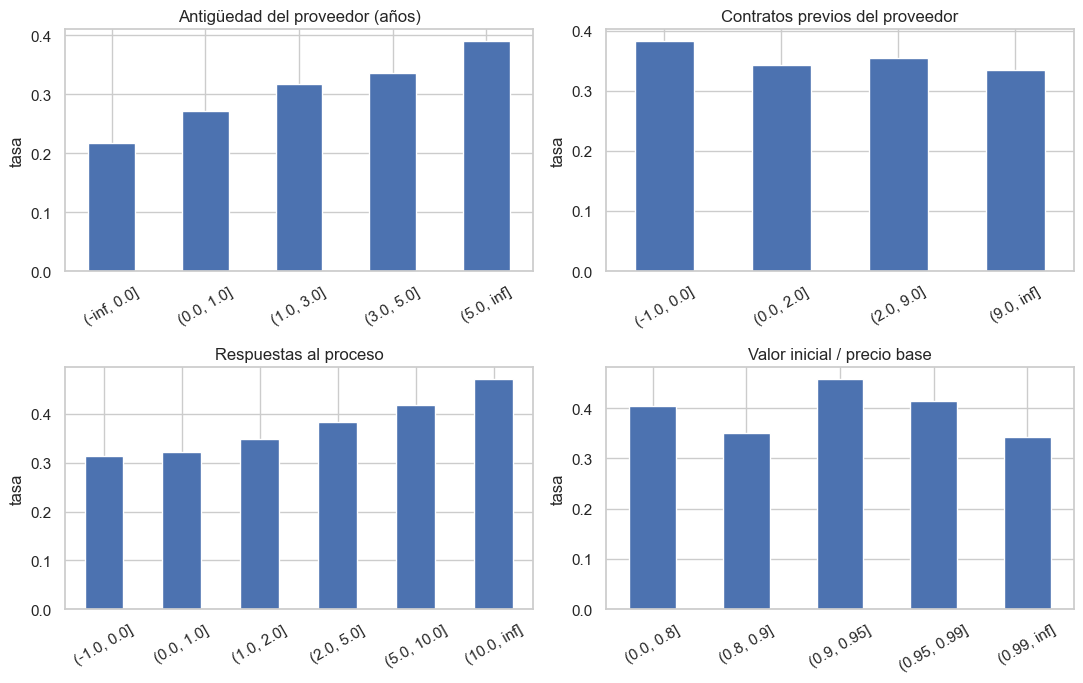


Tasa por condición de pyme y tipo de documento del proveedor:
             contratos     y  valor  tiempo
prov_espyme                                
NO                6601 0.299  0.054   0.257
SI               20458 0.335  0.134   0.227
                      contratos     y  valor  tiempo
tipodocproveedor                                    
Cédula de Ciudadanía       5579 0.329  0.135   0.221
NIT                       32203 0.362  0.099   0.286
No Definido                2005 0.476  0.115   0.397
Otro                        826 0.420  0.143   0.309

Spearman respuestas ~ ofertas: 0.949 | respuestas ~ proponentes: 0.908
Respuestas iguales a ofertas y a proponentes, por año (%):
      ofertas  proponentes
anio                      
2019   50.300       47.700
2020   37.400       36.500
2021   47.900       43.800
2022   50.900       45.700
2023   56.600       49.900
2024   53.200       48.300
2025   60.100       55.300

Tasa según proponentes en Ofertas:
             contratos     y  val

In [18]:
df["antiguedad_prov"] = (df["firma"] - fecha(df["prov_fecha_creacion"])
                         ).dt.days / 365.25
df["previos_prov"] = df.groupby("codigo_proveedor").cumcount()
df["respuestas"] = numero(df["respuestas_al_procedimiento"])
df["inicial_sobre_base"] = (df["valor_inicial"] / precio_base).where(
    df["fuente_valor"] != "precio base")

print("Proveedor registrado después de la firma:",
      f"{(df['antiguedad_prov'] < 0).mean():.1%}")
grupos = {
    "antiguedad_prov": [-np.inf, 0, 1, 3, 5, np.inf],
    "previos_prov": [-1, 0, 2, 9, np.inf],
    "respuestas": [-1, 0, 1, 2, 5, 10, np.inf],
    "inicial_sobre_base": [0, 0.8, 0.9, 0.95, 0.99, np.inf],
}
fig, ax = plt.subplots(2, 2, figsize=(11, 7))
for eje, (var, cortes) in zip(ax.flat, grupos.items()):
    t = tasas(df.assign(rango=pd.cut(df[var], cortes)), "rango")
    print(f"\n{var} (cobertura {df[var].notna().mean():.1%}, Spearman "
          f"con y {spearman(df, var, 'y'):.3f})")
    print(t.to_string())
    t["y"].plot.bar(ax=eje, title=etiqueta(var), rot=30)
    eje.set(xlabel="", ylabel="tasa")
guardar_figura("08_proveedor_competencia")

print("\nTasa por condición de pyme y tipo de documento del proveedor:")
print(tasas(df, "prov_espyme").to_string())
print(tasas(df, "tipodocproveedor", MIN_ENT).to_string())

con_ofertas = df[df["n_ofertas"].notna()]
print(f"\nSpearman respuestas ~ ofertas: "
      f"{spearman(con_ofertas, 'respuestas', 'n_ofertas'):.3f} | "
      f"respuestas ~ proponentes: "
      f"{spearman(con_ofertas, 'respuestas', 'proponentes'):.3f}")
print("Respuestas iguales a ofertas y a proponentes, por año (%):")
print((pd.DataFrame({
    "ofertas": con_ofertas["respuestas"] == con_ofertas["n_ofertas"],
    "proponentes": con_ofertas["respuestas"] == con_ofertas["proponentes"],
}).groupby(con_ofertas["anio"]).mean() * 100).round(1).to_string())
print("\nTasa según proponentes en Ofertas:")
print(tasas(con_ofertas.assign(rango=pd.cut(
    con_ofertas["proponentes"], [0, 1, 2, 5, 10, np.inf])), "rango")
      .to_string())

**Hallazgos.**

1. Los proveedores con más antigüedad en SECOP II tienen más adiciones: 27,2 % con un año o menos frente a 39,1 % con más de cinco años.
2. Los contratos previos del proveedor dentro del periodo no muestran relación (Spearman -0,04).
3. Más respuestas al proceso se asocian con más adiciones: 31,3 % sin respuestas y 47,1 % con más de 10. La relación probablemente refleja que los procesos competidos son de mayor valor.
4. Un valor inicial muy por debajo del precio base (razón de 0,8 o menos) casi duplica la tasa de adición en valor frente a adjudicar cerca del precio base (17,9 % y 10,0 %).
5. Las pymes tienen más adición en valor (13,4 %) que las no pymes (5,4 %).
6. El número de proponentes en Ofertas también se asocia con más adiciones (32,8 % con un proponente y 43,9 % con más de 10). Las respuestas de Procesos ordenan los procesos casi igual (Spearman 0,95), aunque el conteo exacto coincide solo entre 37 % y 60 % según el año. Se conservan ambas: respuestas por su cobertura total y proponentes como medida directa de competencia.

## 13. Objeto, financiación y tiempos del proceso

Variables que los antecedentes reportan como relevantes y que aún no se
habían evaluado:

1. Segmento UNSPSC del objeto contratado (Rodríguez Arévalo, 2021; Salazar
   Mejía, 2024).
2. Fuente principal de los recursos y destino del gasto. Los montos por
   fuente se comparan con el valor inicial para saber si también se
   actualizan con las adiciones.
3. Condiciones de entrega y opción de prórroga pactada.
4. Días entre la publicación y la adjudicación del proceso, entre la
   adjudicación y la firma, y entre la firma y el inicio (Salazar Mejía,
   2024). Se verifica si la fecha de inicio se conoce al firmar.

Suma de montos por fuente / valor inicial (mediana):
y_valor
0   1.000
1   1.284

segmento_unspsc (n >= 300):
                 contratos     y  valor  tiempo
segmento_unspsc                                
72                   22908 0.377  0.119   0.284
83                     610 0.369  0.103   0.300
30                     489 0.350  0.108   0.256
81                    2840 0.339  0.106   0.256
77                     375 0.339  0.072   0.283
80                     960 0.326  0.066   0.275
95                    3261 0.309  0.031   0.286
70                     568 0.210  0.060   0.164
93                     312 0.179  0.077   0.112

fuente_principal (n >= 300):
                       contratos     y  valor  tiempo
fuente_principal                                     
Crédito                      674 0.580  0.074   0.547
Regalías                    1455 0.444  0.094   0.381
PGN                         7637 0.412  0.136   0.307
Propios                     6424 0.371  0.100   0.292
Propios 

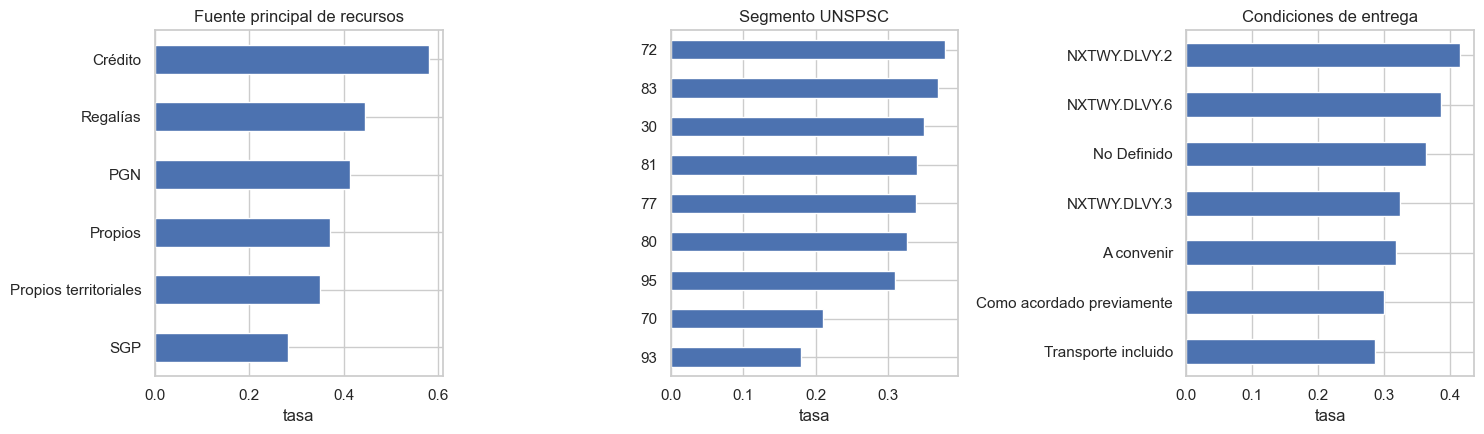

In [19]:
df["segmento_unspsc"] = df["codigo_de_categoria_principal"].str.extract(
    r"V1\.(\d{2})")[0]
FUENTES = {
    "presupuesto_general_de_la_nacion_pgn": "PGN",
    "sistema_general_de_participaciones": "SGP",
    "sistema_general_de_regal_as": "Regalías",
    "recursos_propios_alcald_as_gobernaciones_y_resguardos_ind_genas_":
        "Propios territoriales",
    "recursos_de_credito": "Crédito",
    "recursos_propios": "Propios",
}
montos = df[list(FUENTES)].apply(numero).fillna(0).rename(columns=FUENTES)
total = montos.sum(axis=1)
df["fuente_principal"] = montos.idxmax(axis=1).where(total > 0)
print("Suma de montos por fuente / valor inicial (mediana):")
print((total / df["valor_inicial"]).where(total > 0)
      .groupby(df["y_valor"]).median().round(3).to_string())

adjudicacion = fecha(df["fecha_adjudicacion"])
df["dias_publicacion_adjudicacion"] = (adjudicacion
                                       - df["publicacion"]).dt.days
df["dias_adjudicacion_firma"] = (df["firma"] - adjudicacion).dt.days
df["dias_firma_inicio"] = (df["inicio"] - df["firma"]).dt.days

categoricas = {"segmento_unspsc": 300, "fuente_principal": 300,
               "destino_gasto": 300, "condiciones_de_entrega": 300,
               "el_contrato_puede_ser_prorrogado": 0}
for var, minimo in categoricas.items():
    print(f"\n{var} (n >= {minimo}):")
    print(tasas(df, var, minimo).sort_values("y", ascending=False)
          .to_string())

tiempos = ["dias_publicacion_adjudicacion", "dias_adjudicacion_firma",
           "dias_firma_inicio"]
resumen = pd.DataFrame({
    "cobertura": df[tiempos].notna().mean(),
    "mediana y=0": df.loc[df["y"] == 0, tiempos].median(),
    "mediana y=1": df.loc[df["y"] == 1, tiempos].median(),
    "spearman con y": [spearman(df, v, "y") for v in tiempos],
})
print("\nTiempos del proceso (días):")
print(resumen.round(3).to_string())
posterior = (df["inicio"] > df["firma"]).mean()
mismo_dia = (df["inicio"].dt.date == df["firma"].dt.date).mean()
print(f"\nInicio posterior a la firma: {posterior:.1%} | inicio el mismo día: "
      f"{mismo_dia:.1%}")

fig, ax = plt.subplots(1, 3, figsize=(15, 4.5))
for eje, var in zip(ax, ["fuente_principal", "segmento_unspsc",
                         "condiciones_de_entrega"]):
    tasas(df, var, 300)["y"].sort_values().plot.barh(ax=eje,
                                                     title=etiqueta(var))
    eje.set(xlabel="tasa", ylabel="")
guardar_figura("10_objeto_financiacion")

**Hallazgos.**

1. Por fuente principal de recursos, crédito (58,0 %, n = 674), regalías (44,4 %) y PGN (41,2 %) tienen más adiciones que SGP (28,2 %).
2. Los montos por fuente suman el valor actual del contrato: frente al valor inicial, su mediana es 1,28 con adición en valor y 1,00 sin ella. Solo la fuente principal es utilizable, y aun así puede cambiar si una adición se financia con otra fuente.
3. El segmento UNSPSC 72 (servicios de construcción) reúne 22.908 contratos con 37,7 % de adición; el 95 (terrenos, edificios y vías) casi no tiene adición en valor (3,1 %). El 16,0 % de los contratos no tiene segmento definido.
4. Los contratos de inversión tienen más adiciones que los de funcionamiento (37,8 % y 31,6 %).
5. Las entregas "A convenir" (31,9 %) y "Como acordado previamente" (30,0 %) tienen menos adiciones que el código NXTWY.DLVY.2 (41,6 %), en línea con Salazar Mejía (2024). Tres categorías llegan como códigos sin etiqueta.
6. La opción de prórroga pactada no se asocia con la adición en tiempo (28,0 % con opción y 28,3 % sin ella), por lo que no filtra el desenlace.
7. Los contratos con adición tardan más entre la publicación y la adjudicación (mediana de 26 frente a 19 días).
8. La fecha de inicio es posterior a la firma en el 93,0 % de los contratos y solo el 14,0 % inicia el mismo día. Los días entre firma e inicio no se conocen al firmar y se tratan como variable posterior.

## 14. Garantías

1. Se mide la cobertura de la tabla de Garantías por año de firma.
2. Se compara la fecha de creación de las pólizas con la fecha de firma.

In [20]:
garantias["creacion"] = fecha(garantias["fechadecreacionpoliza"])
por_contrato = garantias.groupby("id_contrato").agg(
    n_polizas=("tipopoliza", "size"), primera_poliza=("creacion", "min"))
df = df.merge(por_contrato, how="left", left_on="id_contrato",
              right_index=True)
df["n_polizas"] = df["n_polizas"].fillna(0)
print("Cobertura de Garantías por año de firma (%):")
print((df["n_polizas"].gt(0).groupby(df["anio"]).mean() * 100)
      .round(1).to_string())

con_poliza = df[df["n_polizas"] > 0]
dias_a_poliza = (con_poliza["primera_poliza"] - con_poliza["firma"]).dt.days
print(f"\nContratos con póliza: {len(con_poliza):,}. Días entre la firma y "
      "la primera póliza:")
print(dias_a_poliza.describe(percentiles=[.1, .5, .9]).round(1).to_string())

Cobertura de Garantías por año de firma (%):
anio
2019   0.300
2020   0.700
2021   0.700
2022   0.500
2023   0.700
2024   0.700
2025   2.400

Contratos con póliza: 429. Días entre la firma y la primera póliza:
count     429.000
mean      457.600
std       457.400
min        -3.000
10%        33.800
50%       302.000
90%     1,050.400
max     2,428.000


**Hallazgos.**

1. La cobertura es menor al 2,5 % en todos los años.
2. La primera póliza registrada se crea, en mediana, 302 días después de la firma, por lo que la tabla refleja sobre todo pólizas de modificaciones y no las garantías pactadas al firmar.
3. Garantías no se usa como fuente de variables mientras la tabla siga incompleta.

## 15. Fuga de información

1. Se calcula el AUC de cada variable por sí sola frente a `y`.
2. Numéricas: AUC directo sobre los valores no nulos, tomando el máximo entre
   AUC y 1 - AUC.
3. Categóricas: tasa por categoría calculada fuera del pliegue (5 pliegues
   estratificados), para no premiar categorías raras.
4. Las variables se separan entre disponibles al firmar y posteriores a la
   firma. Una variable posterior con AUC alto confirma fuga; un AUC cercano a
   0,5 indica que la variable no aporta señal por sí sola.
5. La entidad se evalúa además con partición temporal: tasas de 2019 a 2023,
   suavizadas hacia la tasa global, aplicadas a los contratos de 2024.
6. Se calcula la correlación de Spearman entre las variables numéricas de
   firma para detectar redundancia.

                        variable   momento   auc
                 estado_contrato posterior 0.864
                   exceso_fechas posterior 0.760
          valor_sobre_adjudicado posterior 0.704
                  nombre_entidad     firma 0.669
                    valor_actual posterior 0.660
                   valor_inicial     firma 0.646
                  plazo_contrato posterior 0.646
   dias_publicacion_adjudicacion     firma 0.603
       modalidad_de_contratacion     firma 0.601
      justificacion_modalidad_de     firma 0.598
               dias_firma_inicio posterior 0.597
                   plazo_inicial     firma 0.575
                      respuestas     firma 0.567
         dias_adjudicacion_firma     firma 0.560
                     prov_espyme     firma 0.559
               prov_tipo_empresa     firma 0.558
                 antiguedad_prov     firma 0.558
                     proponentes     firma 0.554
                    departamento     firma 0.551
                fuen

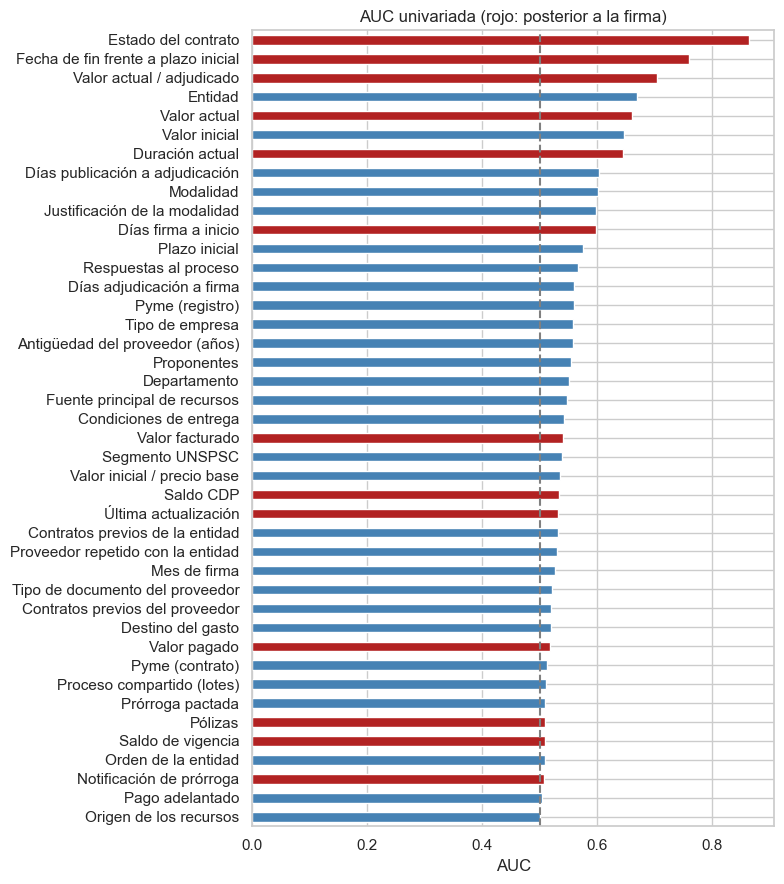

In [21]:
def auc_numerica(x, y):
    validos = x.notna()
    auc = roc_auc_score(y[validos], x[validos])
    return max(auc, 1 - auc)


def auc_categorica(x, y, pliegues=5):
    x = x.fillna("NA").astype(str).to_numpy()
    y = y.to_numpy()
    pred = np.zeros(len(y))
    cv = StratifiedKFold(pliegues, shuffle=True, random_state=42)
    for tr, te in cv.split(x, y):
        tasa = pd.Series(y[tr]).groupby(x[tr]).mean()
        pred[te] = pd.Series(x[te]).map(tasa).fillna(y[tr].mean())
    return roc_auc_score(y, pred)


df["ultima_act"] = (fecha(df["ultima_actualizacion"])
                    - pd.Timestamp("2019-01-01")).dt.days
df["notificacion_prorroga"] = df["fecha_de_notificaci_n_de_prorrogaci_n"
                                 ].notna().astype(int)
for v in ["valor_pagado", "valor_facturado", "saldo_cdp", "saldo_vigencia"]:
    df[v + "_n"] = numero(df[v])

firma_num = ["valor_inicial", "plazo_inicial", "mes", "respuestas",
             "inicial_sobre_base", "proponentes", "antiguedad_prov",
             "previos_prov",
             "previos_entidad", "proveedor_repetido", "proceso_compartido",
             "dias_publicacion_adjudicacion", "dias_adjudicacion_firma"]
firma_cat = ["nombre_entidad", "modalidad_de_contratacion", "departamento",
             "orden", "origen_de_los_recursos", "destino_gasto",
             "tipodocproveedor", "es_pyme", "prov_espyme",
             "prov_tipo_empresa", "condiciones_de_entrega",
             "habilita_pago_adelantado", "justificacion_modalidad_de",
             "segmento_unspsc", "fuente_principal",
             "el_contrato_puede_ser_prorrogado"]
posterior_num = ["valor_actual", "valor_sobre_adjudicado", "plazo_contrato",
                 "exceso_fechas", "valor_pagado_n", "valor_facturado_n",
                 "saldo_cdp_n", "saldo_vigencia_n", "ultima_act",
                 "n_polizas", "notificacion_prorroga", "dias_firma_inicio"]
posterior_cat = ["estado_contrato"]

filas = (
    [(v, "firma", auc_numerica(df[v], df["y"])) for v in firma_num]
    + [(v, "firma", auc_categorica(df[v], df["y"])) for v in firma_cat]
    + [(v, "posterior", auc_numerica(df[v], df["y"]))
       for v in posterior_num]
    + [(v, "posterior", auc_categorica(df[v], df["y"]))
       for v in posterior_cat]
)
fuga = pd.DataFrame(filas, columns=["variable", "momento", "auc"])
fuga = fuga.sort_values("auc", ascending=False)
print(fuga.round(3).to_string(index=False))

colores = fuga["momento"].map({"firma": "steelblue",
                               "posterior": "firebrick"})
ax = fuga.assign(nombre=fuga["variable"].map(etiqueta)).plot.barh(
    x="nombre", y="auc", color=colores, legend=False, figsize=(8, 9),
    title="AUC univariada (rojo: posterior a la firma)")
ax.set(xlabel="AUC", ylabel="")
ax.axvline(0.5, color="gray", ls="--")
ax.invert_yaxis()
guardar_figura("09_fuga_auc")

Entidad con partición temporal (2019-2023 a 2024): AUC 0.635 | contratos de 2024 en entidades no vistas: 13.3%



Pares con |Spearman| >= 0,5:
Valor inicial                    Plazo inicial                       0.588
                                 Días publicación a adjudicación     0.635
Plazo inicial                    Días publicación a adjudicación     0.546
Respuestas al proceso            Proponentes                         0.908
                                 Días publicación a adjudicación     0.534
Contratos previos del proveedor  Proveedor repetido con la entidad   0.649


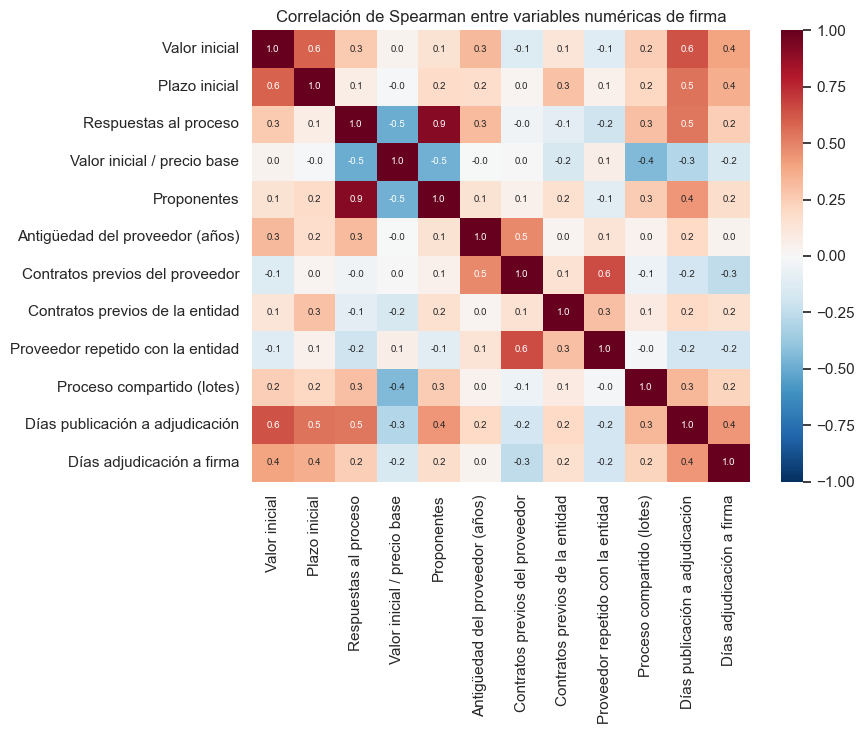

In [22]:
entrena = df[df["anio"] <= 2023]
prueba = df[df["anio"] == 2024]
base = entrena["y"].mean()
conteo = entrena.groupby("nombre_entidad")["y"].agg(["sum", "count"])
suavizado = (conteo["sum"] + 10 * base) / (conteo["count"] + 10)
pred = prueba["nombre_entidad"].map(suavizado).fillna(base)
no_vistas = ~prueba["nombre_entidad"].isin(conteo.index)
print(f"Entidad con partición temporal (2019-2023 a 2024): AUC "
      f"{roc_auc_score(prueba['y'], pred):.3f} | contratos de 2024 en "
      f"entidades no vistas: {no_vistas.mean():.1%}")

numericas = [v for v in firma_num if v != "mes"]
correlacion = df[numericas].corr("spearman").rename(
    index=etiqueta, columns=etiqueta)
fuertes = correlacion.where(np.triu(np.ones(correlacion.shape, bool), 1))
print("\nPares con |Spearman| >= 0,5:")
print(fuertes.stack().loc[lambda s: s.abs() >= 0.5].round(3).to_string())
plt.figure(figsize=(9, 7.5))
sns.heatmap(correlacion, cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            annot=True, fmt=".1f", annot_kws={"size": 7})
plt.title("Correlación de Spearman entre variables numéricas de firma")
guardar_figura("12_correlacion")

**Hallazgos.**

1. `estado_contrato` es la variable con mayor AUC (0,86) y confirma la fuga identificada en la sección 4.
2. El exceso de la fecha de fin (0,76), el valor actual sobre el adjudicado (0,70), el valor actual (0,66) y la duración del contrato (0,65) son posteriores a la firma y se excluyen.
3. Las variables de ejecución restantes (pagos, facturación, saldos, última actualización, notificación de prórroga y pólizas) tienen AUC entre 0,50 y 0,54: no aportan señal y tampoco se usan.
4. Entre las variables de firma, las más informativas son la entidad (0,67), el valor inicial (0,65), los días entre publicación y adjudicación (0,60), la modalidad (0,60) y el plazo inicial (0,58). Los días entre firma e inicio (0,60) pasan a posteriores por la sección 13. Ninguna variable de firma supera 0,70 por sí sola, lo que descarta fuga en ellas.
5. El origen de los recursos (0,50), el orden (0,51) y el pago adelantado (0,50) no aportan señal por sí solos.
6. Con partición temporal (tasas de 2019 a 2023 aplicadas a 2024), el AUC de la entidad baja de 0,67 a 0,64: el 13,3 % de los contratos de 2024 es de entidades sin contratos previos. La evaluación del modelo debe ser temporal.
7. Hay redundancia entre variables de firma: respuestas y proponentes (Spearman 0,91), contratos previos del proveedor y proveedor repetido (0,65), valor inicial y días entre publicación y adjudicación (0,64), y valor y plazo iniciales (0,59). De cada par muy correlacionado conviene conservar una variable en los modelos lineales.

## 16. Contraste con el estado del arte

1. **Variable objetivo.** Rodríguez Arévalo (2021) define la ineficiencia como prórroga o sobrecosto y reporta 23 % en 8.635 contratos de Bogotá (2016 a 2020); Gallego et al. (2021) reportan 11 % a nivel nacional. La tasa de obra de este EDA (36,4 %) es mayor, coherente con la complejidad de las obras. Salazar Mejía (2024) usa el conteo de adiciones en valor; en obra la mediana es 1, por lo que se conserva la variable binaria.
2. **Fuga en los antecedentes.** Ambos estudios usan el valor del contrato y plazos calculados con la fecha de fin (firma a fin e inicio a fin). La sección 3 muestra que esas variables incorporan las adiciones; Rodríguez Arévalo incluye además pagos y facturación. Sus métricas (precisión de 0,92 y MAP@100 de 1,00) probablemente son optimistas para un uso al momento de la firma.
3. **Partición.** Ambos estudios usan particiones aleatorias (70/30 y 85/15). El cambio en el registro de días adicionados (sección 2) hace necesaria la partición temporal.
4. **Muestra.** Salazar Mejía filtra por estado "Modificado", "terminado" o "cerrado". La sección 4 muestra que el estado depende del desenlace; aquí la muestra se define por fecha de firma.
5. **Hallazgos que se confirman.** El valor es la variable más importante en ambos estudios; aquí la tasa sube de 16,6 % a 55,8 % entre deciles de valor inicial. La entidad es la principal variable en Salazar Mejía; aquí tiene el mayor AUC entre las variables de firma (0,67). El ciclo fiscal se refleja en más adición en tiempo en noviembre y diciembre. La entrega "a convenir" se asocia con menos adiciones, como en Salazar Mejía. La contratación directa casi no registra adición en valor (2,8 %), como encontró Rodríguez Arévalo.
6. **Hallazgos que no se replican.** El destino del gasto, el origen de los recursos y los contratos previos del proveedor tienen poca señal por sí solos (AUC de 0,52, 0,50 y 0,52).
7. **Variables derivadas de los antecedentes.** La fuente principal de recursos, los días entre publicación y adjudicación y la relación previa entre entidad y contratista aportan señal moderada (AUC de 0,55, 0,60 y 0,53) y se suman a las candidatas.
8. **Métricas.** Rodríguez Arévalo prioriza la precisión con un umbral conservador (exhaustividad de 0,25) y Salazar Mejía usa MAP@K. PR-AUC y precisión en k recogen ambos enfoques.
9. **Uso responsable.** Reina Hidalgo (2026) advierte que un modelo entrenado con datos históricos puede reproducir sesgos y que las decisiones de "caja negra" chocan con la transparencia. Las tasas difieren por condición de pyme (33,5 % y 29,9 %), por tipo de documento del proveedor y por departamento (18,5 % a 50,6 %). Por eso el modelo solo prioriza la vigilancia, nunca evalúa ofertas, y cada alerta se acompaña de su explicación (SHAP) y de revisión humana.

## 17. Conclusiones para el modelado

1. **Muestra.** Contratos de obra firmados entre 2019 y 2025 definidos por fecha de firma, sin filtrar por estado. Se excluyen solo los contratos con plazo inicial vigente.
2. **Variable objetivo.** Binaria y registrada (acto legal de adición en tiempo o en valor), con tasa de 36,4 %. La definición ampliada de la sección 3 queda solo como análisis de sensibilidad. Se entrenan un modelo combinado y dos por tipo de adición, porque tiempo y valor tienen perfiles distintos. La extensión relativa del plazo se reporta como magnitud en el tablero.
3. **Variables.** Valor inicial (adjudicado, oferta ganadora o precio base, en logaritmo), plazo inicial, modalidad agrupada, departamento, entidad, mes de firma, respuestas al proceso (o proponentes, no ambas), proceso compartido, razón valor inicial sobre precio base, días entre publicación y adjudicación, segmento UNSPSC, fuente principal de recursos, destino del gasto, condiciones de entrega, experiencia de la entidad, proveedor repetido, antigüedad del proveedor, condición de pyme y tipo de documento del proveedor, con indicadores de faltante.
4. **Exclusiones por fuga.** `estado_contrato`, `valor_del_contrato`, `duraci_n_del_contrato`, `fecha_de_fin_del_contrato`, `dias_adicionados`, días entre firma e inicio, montos por fuente de recursos y todas las variables de ejecución.
5. **Partición temporal.** Entrenamiento 2019 a 2023, validación 2024 y prueba 2025. Por el cambio en el registro de las adiciones (más días adicionados y menos adiciones en valor registradas con los años), se reportan métricas por año y se recalibra la probabilidad con el año más reciente.
6. **Entidad.** Codificación por tasa con suavizado calculada dentro de cada pliegue y evaluación temporal (AUC univariado de 0,64 en 2024, con 13,3 % de entidades no vistas).
7. **Métricas.** PR-AUC y precisión en k como métricas principales, con AUC-ROC como referencia.
8. **Fuentes.** Ofertas se usa con sus tres tablas (proponentes y oferta ganadora). Garantías queda fuera hasta que la tabla se complete.
9. **Uso responsable.** Explicación SHAP por alerta, revisión humana y seguimiento de las tasas de alerta por tipo de proveedor y departamento.
10. **Limitaciones.** Subregistro de la adición en valor en la tabla Adiciones: el modelo predice adiciones registradas, y la tasa real de crecimiento del valor es mayor (sección 3); cobertura de 66,6 % en Proveedores y cambio en el registro de días adicionados a lo largo del periodo.